RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =           10     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  5.68980D+00    |proj g|=  8.10722D-02


 This problem is unconstrained.



At iterate    5    f=  5.57782D+00    |proj g|=  1.63291D-02

At iterate   10    f=  5.56809D+00    |proj g|=  1.14696D-02

At iterate   15    f=  5.56441D+00    |proj g|=  8.25481D-03

At iterate   20    f=  5.52275D+00    |proj g|=  2.07567D-02

At iterate   25    f=  5.52159D+00    |proj g|=  2.35377D-03

At iterate   30    f=  5.52058D+00    |proj g|=  2.76615D-03

At iterate   35    f=  5.52052D+00    |proj g|=  5.63348D-05

At iterate   40    f=  5.52052D+00    |proj g|=  7.28682D-04

At iterate   45    f=  5.52047D+00    |proj g|=  1.49825D-03


/Users/visjostr/school/parking-prediction/.venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "



At iterate   50    f=  5.52046D+00    |proj g|=  5.79436D-04

           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cauchy searches
Skip  = number of BFGS updates skipped
Nact  = number of active bounds at final generalized Cauchy point
Projg = norm of the final projected gradient
F     = final function value

           * * *

   N    Tit     Tnf  Tnint  Skip  Nact     Projg        F
   10     50     58      1     0     0   5.794D-04   5.520D+00
  F =   5.5204573105837431     

STOP: TOTAL NO. of ITERATIONS REACHED LIMIT                 
                     Parkings  day_of_year  weekday  hour  is_holiday
2021-10-11 00:00:00         1          284        1     0           0
2021-10-11 01:00:00         1          284        1     1           0
2021-10-11 02:00:00         2          284        1     2           0
2021-10-11 03:00:00         2          284        1     3           0
2021-10-11 

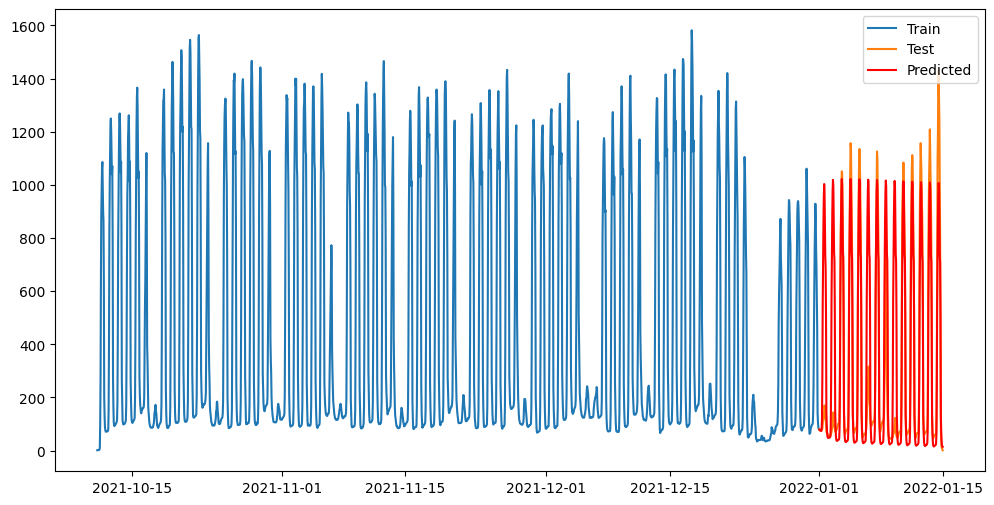

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from datetime import datetime

# Load the dataset
df = pd.read_csv('../preprocess/parking_time_series_with_features_1_hour.csv', delimiter=',')

# Parse the 'Time' column to datetime and set it as index
df['Time'] = pd.to_datetime(df['Time'])
df.set_index('Time', inplace=True)
df.sort_index(inplace=True)

# Split the data into training and test sets
end_date = datetime(2022, 1, 1)
train_data = df[df.index < end_date]
test_data = df[df.index >= end_date]

# Ensure the training data index has a frequency set
train_data.index = pd.DatetimeIndex(train_data.index.values, freq=train_data.index.inferred_freq)

# Define SARIMA model parameters (p, d, q) and seasonal parameters (P, D, Q, m)
p = 2
d = 1
q = 5
P = 1
D = 1
Q = 1
m = 24  # Assuming weekly seasonality

# Fit the SARIMA model
model = SARIMAX(train_data['Parkings'], order=(p, d, q), seasonal_order=(P, D, Q, m))
sarima_results = model.fit()

# Predict using the fitted model
predictions = sarima_results.predict(start=test_data.index[0], end=test_data.index[-1], dynamic=False)

# Print the data and predictions
print(train_data)
print(test_data)
print(predictions)

# Plot the actual vs predicted values
plt.figure(figsize=(12, 6))
plt.plot(train_data.index, train_data['Parkings'], label='Train')
plt.plot(test_data.index, test_data['Parkings'], label='Test')
plt.plot(test_data.index, predictions, label='Predicted', color='red')
plt.legend()
plt.show()


 This problem is unconstrained.


RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =            9     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  5.69860D+00    |proj g|=  5.69674D-02

At iterate    5    f=  5.69699D+00    |proj g|=  1.26790D-03

At iterate   10    f=  5.69606D+00    |proj g|=  2.36069D-02

At iterate   15    f=  5.69406D+00    |proj g|=  6.76365D-04

           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cauchy searches
Skip  = number of BFGS updates skipped
Nact  = number of active bounds at final generalized Cauchy point
Projg = norm of the final projected gradient
F     = final function value

           * * *

   N    Tit     Tnf  Tnint  Skip  Nact     Projg        F
    9     18     21      1     0     0   2.287D-05   5.694D+00
  F =   5.6940574812126119     

CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH             
        

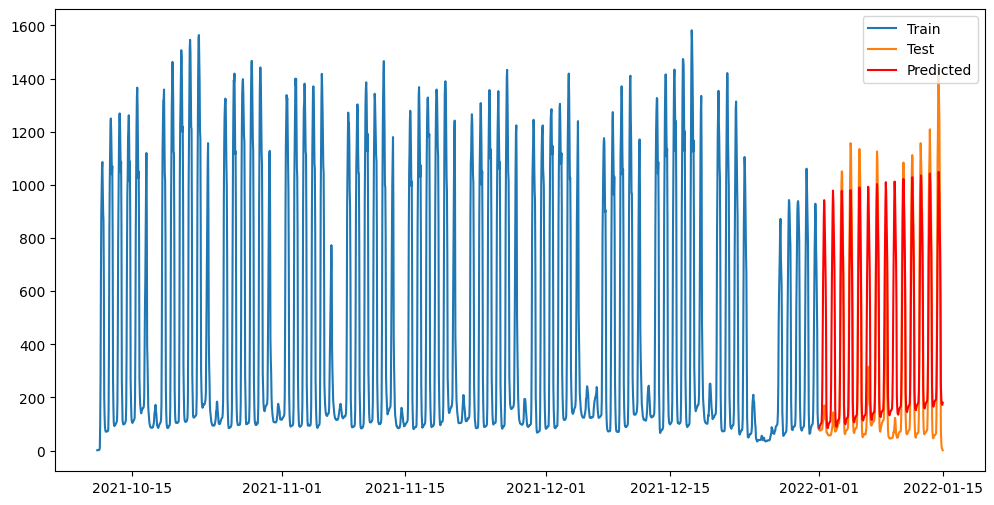

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from datetime import datetime

# Load the dataset
df = pd.read_csv('../preprocess/parking_time_series_with_features_1_hour.csv', delimiter=',')

# Parse the 'Time' column to datetime and set it as index
df['Time'] = pd.to_datetime(df['Time'])
df.set_index('Time', inplace=True)
df.sort_index(inplace=True)

# Convert exogenous features to appropriate data types
df['day_of_year'] = df['day_of_year'].astype(int)
df['weekday'] = df['weekday'].astype(int)
df['hour'] = df['hour'].astype(int)
df['is_holiday'] = df['is_holiday'].astype(int)

exogenous_features = ["day_of_year", "weekday", "hour", "is_holiday"]

# Split the data into training and test sets
end_date = datetime(2022, 1, 1)
train_data = df[df.index < end_date]
test_data = df[df.index >= end_date]

# Ensure the training data index has a frequency set
train_data.index = pd.DatetimeIndex(train_data.index.values, freq="h")

# Extract exogenous features for training and test sets
train_exog = train_data[exogenous_features]
test_exog = test_data[exogenous_features]

# Define SARIMA model parameters (p, d, q) and seasonal parameters (P, D, Q, m)
p = 2
d = 1
q = 0
P = 2
D = 1
Q = 0
m = 24  # Assuming weekly seasonality

# Fit the SARIMA model
model = SARIMAX(train_data['Parkings'], 
                order=(p, d, q), 
                seasonal_order=(P, D, Q, m),
                exog=train_exog,
                )
sarima_results = model.fit()

# Predict using the fitted model

predictions = sarima_results.predict(start=test_data.index[0], 
                                     end=test_data.index[-1], 
                                     exog=test_data[exogenous_features],
                                     dynamic=False)

# Print the data and predictions
print(train_data)
print(test_data)
print(predictions)

# Plot the actual vs predicted values
plt.figure(figsize=(12, 6))
plt.plot(train_data.index, train_data['Parkings'], label='Train')
plt.plot(test_data.index, test_data['Parkings'], label='Test')
plt.plot(test_data.index, predictions, label='Predicted', color='red')
plt.legend()
plt.show()


/Users/visjostr/school/parking-prediction/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/Users/visjostr/school/parking-prediction/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =            8     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  3.46025D+00    |proj g|=  1.26721D-01


 This problem is unconstrained.



At iterate    5    f=  3.35749D+00    |proj g|=  1.07289D-01

At iterate   10    f=  3.32760D+00    |proj g|=  4.92091D-03

At iterate   15    f=  3.32124D+00    |proj g|=  4.02058D-02

At iterate   20    f=  3.31738D+00    |proj g|=  1.83482D-03

At iterate   25    f=  3.31696D+00    |proj g|=  4.72082D-03

At iterate   30    f=  3.31474D+00    |proj g|=  3.63566D-03

At iterate   35    f=  3.31394D+00    |proj g|=  4.02329D-03

At iterate   40    f=  3.31390D+00    |proj g|=  1.31086D-03

At iterate   45    f=  3.31373D+00    |proj g|=  3.20851D-03

At iterate   50    f=  3.31340D+00    |proj g|=  7.22273D-04

           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cauchy searches
Skip  = number of BFGS updates skipped
Nact  = number of active bounds at final generalized Cauchy point
Projg = norm of the final projected gradient
F     = final function value

           * * *

   N    Tit     Tn

/Users/visjostr/school/parking-prediction/.venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


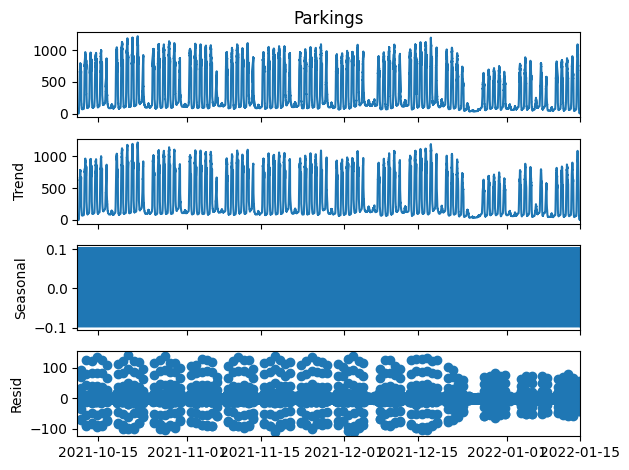

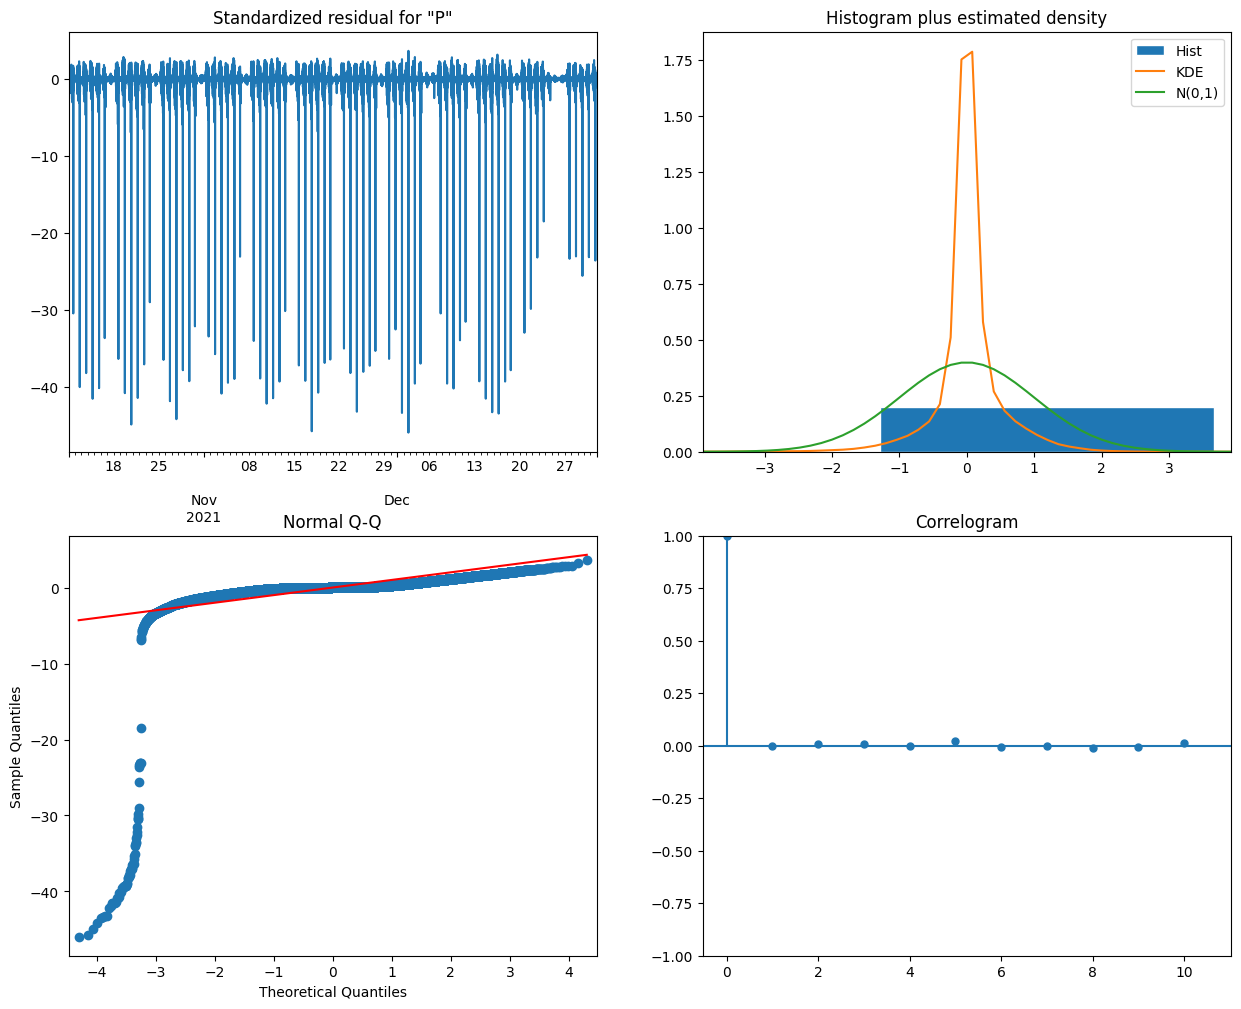

                     Parkings  day_of_year  weekday  hour  is_holiday
2021-10-11 00:10:00         1          284        1     0           0
2021-10-11 00:11:00         1          284        1     0           0
2021-10-11 00:12:00         1          284        1     0           0
2021-10-11 00:13:00         1          284        1     0           0
2021-10-11 00:14:00         1          284        1     0           0
...                       ...          ...      ...   ...         ...
2021-12-31 23:55:00        78          365        5    23           0
2021-12-31 23:56:00        78          365        5    23           0
2021-12-31 23:57:00        78          365        5    23           0
2021-12-31 23:58:00        78          365        5    23           0
2021-12-31 23:59:00        78          365        5    23           0

[118070 rows x 5 columns]
                     Parkings  day_of_year  weekday  hour  is_holiday
Time                                                           

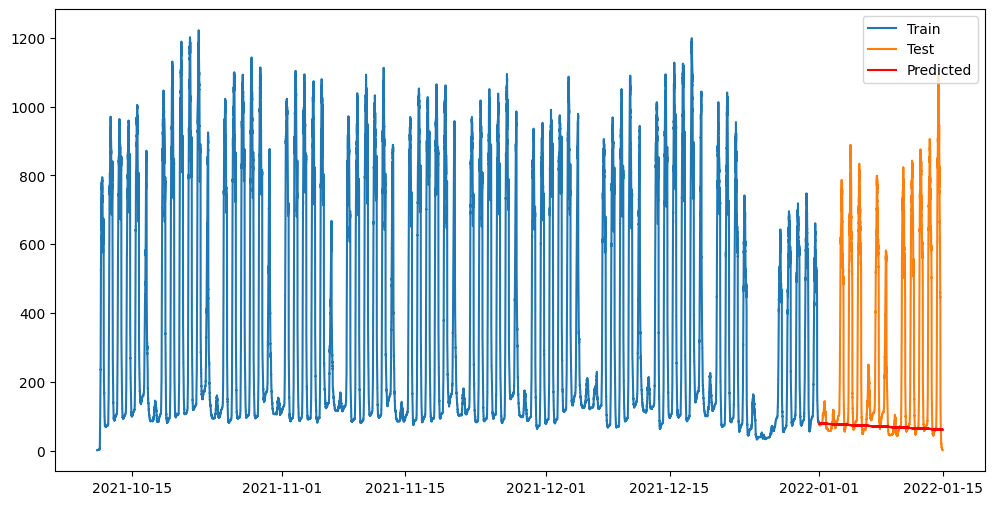

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.seasonal import seasonal_decompose
from datetime import datetime

# Load the dataset
df = pd.read_csv('../preprocess/parking_time_series_with_features.csv', delimiter=',')

# Parse the 'Time' column to datetime and set it as index
df['Time'] = pd.to_datetime(df['Time'])
df.set_index('Time', inplace=True)
df.sort_index(inplace=True)

# Seasonal decomposition to understand the components
decomposition = seasonal_decompose(df['Parkings'], model='additive', period=7)
decomposition.plot()
#plt.show()

# Split the data into training and test sets
end_date = datetime(2022, 1, 1)
train_data = df[df.index < end_date]
test_data = df[df.index >= end_date]

# Ensure the training data index has a frequency set
train_data.index = pd.DatetimeIndex(train_data.index.values, freq=train_data.index.inferred_freq)

# Define SARIMA model parameters (p, d, q) and seasonal parameters (P, D, Q, m)
p = 3
d = 1
q = 2
P = 1
D = 1
Q = 1
m = 7  # Assuming weekly seasonality

# Fit the SARIMA model
model = SARIMAX(train_data['Parkings'], order=(p, d, q), seasonal_order=(P, D, Q, m))
sarima_results = model.fit()

# Model diagnostics
sarima_results.plot_diagnostics(figsize=(15, 12))
plt.show()

# Predict using the fitted model
predictions = sarima_results.predict(start=test_data.index[0], end=test_data.index[-1], dynamic=False)

# Print the data and predictions
print(train_data)
print(test_data)
print(predictions)

# Plot the actual vs predicted values
plt.figure(figsize=(12, 6))
plt.plot(train_data.index, train_data['Parkings'], label='Train')
plt.plot(test_data.index, test_data['Parkings'], label='Test')
plt.plot(test_data.index, predictions, label='Predicted', color='red')
plt.legend()
plt.show()


/Users/visjostr/school/parking-prediction/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/Users/visjostr/school/parking-prediction/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =            8     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  5.39593D+00    |proj g|=  4.08758D-01


 This problem is unconstrained.



At iterate    5    f=  5.27180D+00    |proj g|=  5.68998D-02

At iterate   10    f=  5.24109D+00    |proj g|=  1.09001D-01

At iterate   15    f=  5.20610D+00    |proj g|=  2.05254D-02

At iterate   20    f=  5.16491D+00    |proj g|=  2.26464D-02

At iterate   25    f=  5.16072D+00    |proj g|=  1.98355D-03

At iterate   30    f=  5.15625D+00    |proj g|=  2.18234D-02

At iterate   35    f=  5.15504D+00    |proj g|=  1.33873D-03

At iterate   40    f=  5.15315D+00    |proj g|=  2.88165D-02

At iterate   45    f=  5.15087D+00    |proj g|=  2.66330D-03


/Users/visjostr/school/parking-prediction/.venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "



At iterate   50    f=  5.15078D+00    |proj g|=  1.66700D-03

           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cauchy searches
Skip  = number of BFGS updates skipped
Nact  = number of active bounds at final generalized Cauchy point
Projg = norm of the final projected gradient
F     = final function value

           * * *

   N    Tit     Tnf  Tnint  Skip  Nact     Projg        F
    8     50     62      1     0     0   1.667D-03   5.151D+00
  F =   5.1507824724121232     

STOP: TOTAL NO. of ITERATIONS REACHED LIMIT                 
                     Parkings  day_of_year  weekday  hour  is_holiday
2021-10-11 00:00:00         1          284        1     0           0
2021-10-11 00:15:00         1          284        1     0           0
2021-10-11 00:30:00         1          284        1     0           0
2021-10-11 00:45:00         1          284        1     0           0
2021-10-11 

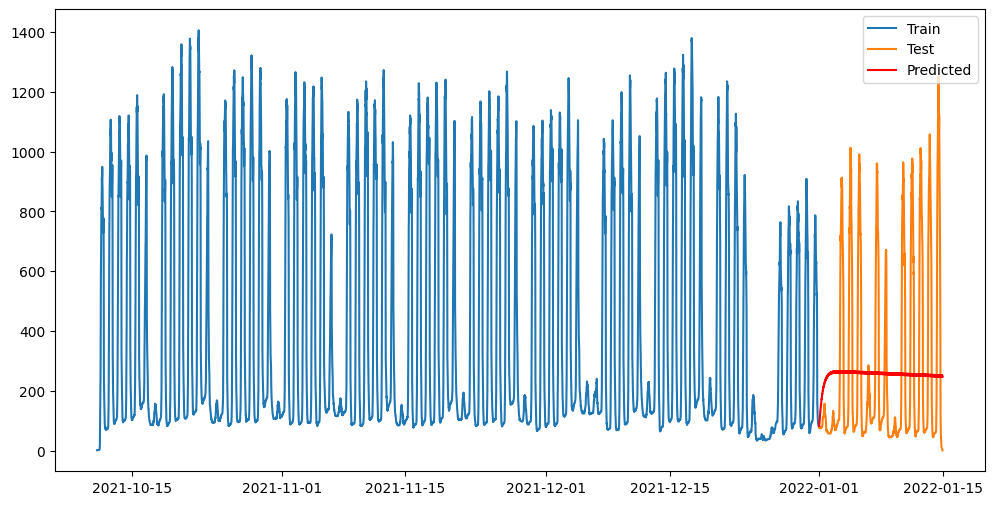

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.seasonal import seasonal_decompose
from datetime import datetime

# Load the dataset
df = pd.read_csv('../preprocess/parking_time_series_with_features_15min.csv', delimiter=',')

# Parse the 'Time' column to datetime and set it as index
df['Time'] = pd.to_datetime(df['Time'])
df.set_index('Time', inplace=True)
df.sort_index(inplace=True)

# Seasonal decomposition
# Since the data is already in 15-minute intervals, we'll directly decompose it
#decomposition = seasonal_decompose(df['Parkings'], model='additive', period=96)  # 96 periods in a day (24 hours * 4 quarters)
#decomposition.plot()
#plt.show()

# Split the data into training and test sets
end_date = datetime(2022, 1, 1)
train_data = df[df.index < end_date]
test_data = df[df.index >= end_date]

# Ensure the training data index has a frequency set (15 minutes)
train_data.index = pd.DatetimeIndex(train_data.index.values, freq='15min')  # '15T' stands for 15-minute frequency

# Define SARIMA model parameters (p, d, q) and seasonal parameters (P, D, Q, m)
p = 3
d = 1
q = 2
P = 1
D = 1
Q = 1
m = 7  # 96 periods in a day (15 minutes * 96 = 24 hours)

# Fit the SARIMA model
model = SARIMAX(train_data['Parkings'], order=(p, d, q), seasonal_order=(P, D, Q, m))
sarima_results = model.fit()

# Model diagnostics
#sarima_results.plot_diagnostics(figsize=(15, 12))
#plt.show()

# Predict using the fitted model
predictions = sarima_results.predict(start=test_data.index[0], end=test_data.index[-1], dynamic=False)

# Print the data and predictions
print(train_data)
print(test_data)
print(predictions)

# Plot the actual vs predicted values
plt.figure(figsize=(12, 6))
plt.plot(train_data.index, train_data['Parkings'], label='Train')
plt.plot(test_data.index, test_data['Parkings'], label='Test')
plt.plot(test_data.index, predictions, label='Predicted', color='red')
plt.legend()
plt.show()


In [ ]:
from sklearn.metrics import mean_squared_error

# Calculate Mean Squared Error (MSE)
mse = mean_squared_error(test_data['Parkings'], predictions)
print(f'Mean Squared Error (MSE): {mse}')



Mean Squared Error (MSE): 54896.58181341379


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.seasonal import seasonal_decompose
from datetime import datetime

# Load the dataset
df = pd.read_csv('../preprocess/parking_time_series_with_features_15min.csv', delimiter=',')

# Parse the 'Time' column to datetime and set it as index
df['Time'] = pd.to_datetime(df['Time'])
df.set_index('Time', inplace=True)
df.sort_index(inplace=True)

df['day_of_year'] = df['day_of_year'].astype(int)
df['weekday'] = df['weekday'].astype(int)
df['hour'] = df['hour'].astype(int)
df['is_holiday'] = df['is_holiday'].astype(int)

# Seasonal decomposition
# Since the data is already in 15-minute intervals, we'll directly decompose it
#decomposition = seasonal_decompose(df['Parkings'], model='additive', period=96)  # 96 periods in a day (24 hours * 4 quarters)
#decomposition.plot()
#plt.show()

exogenous_features = ["day_of_year","weekday","hour","is_holiday"]

from sklearn.preprocessing import StandardScaler

# Scale the exogenous features
scaler = StandardScaler()
df[exogenous_features] = scaler.fit_transform(df[exogenous_features])

print(df[['Parkings'] + exogenous_features].corr())  # Check correlations between target and exogenous features



# Split the data into training and test sets
end_date = datetime(2022, 1, 1)
train_data = df[df.index < end_date]
test_data = df[df.index >= end_date]
# Ensure the training data index has a frequency set (15 minutes)
train_data.index = pd.DatetimeIndex(train_data.index.values, freq='15min')  # '15T' stands for 15-minute frequency

# Split the exogenous features into train and test sets, aligned with the target variable
exogenous_train = df.loc[df.index < end_date, exogenous_features]
exogenous_test = df.loc[df.index >= end_date, exogenous_features]


# Define SARIMA model parameters (p, d, q) and seasonal parameters (P, D, Q, m)
p = 3
d = 1
q = 2
P = 0
D = 1
Q = 0
m = 7  # 96 periods in a day (15 minutes * 96 = 24 hours)

             Parkings  day_of_year   weekday      hour  is_holiday
Parkings     1.000000     0.082201 -0.219631  0.152346   -0.331861
day_of_year  0.082201     1.000000 -0.005760  0.000416   -0.074872
weekday     -0.219631    -0.005760  1.000000 -0.000186    0.578922
hour         0.152346     0.000416 -0.000186  1.000000    0.000090
is_holiday  -0.331861    -0.074872  0.578922  0.000090    1.000000


/Users/visjostr/school/parking-prediction/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/Users/visjostr/school/parking-prediction/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
 This problem is unconstrained.


RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =            6     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  5.58010D+00    |proj g|=  4.74072D-01

At iterate    5    f=  5.48593D+00    |proj g|=  6.91366D-03

At iterate   10    f=  5.46587D+00    |proj g|=  2.12874D-02

At iterate   15    f=  5.45641D+00    |proj g|=  3.26746D-02

At iterate   20    f=  5.44465D+00    |proj g|=  1.04906D-02

At iterate   25    f=  5.44264D+00    |proj g|=  2.58087D-02

At iterate   30    f=  5.44106D+00    |proj g|=  3.67040D-03

At iterate   35    f=  5.44077D+00    |proj g|=  2.75172D-04

At iterate   40    f=  5.44077D+00    |proj g|=  3.94622D-04

At iterate   45    f=  5.44075D+00    |proj g|=  5.01371D-04


/Users/visjostr/school/parking-prediction/.venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "



At iterate   50    f=  5.44075D+00    |proj g|=  1.45944D-04

           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cauchy searches
Skip  = number of BFGS updates skipped
Nact  = number of active bounds at final generalized Cauchy point
Projg = norm of the final projected gradient
F     = final function value

           * * *

   N    Tit     Tnf  Tnint  Skip  Nact     Projg        F
    6     50     63      1     0     0   1.459D-04   5.441D+00
  F =   5.4407475305836188     

STOP: TOTAL NO. of ITERATIONS REACHED LIMIT                 


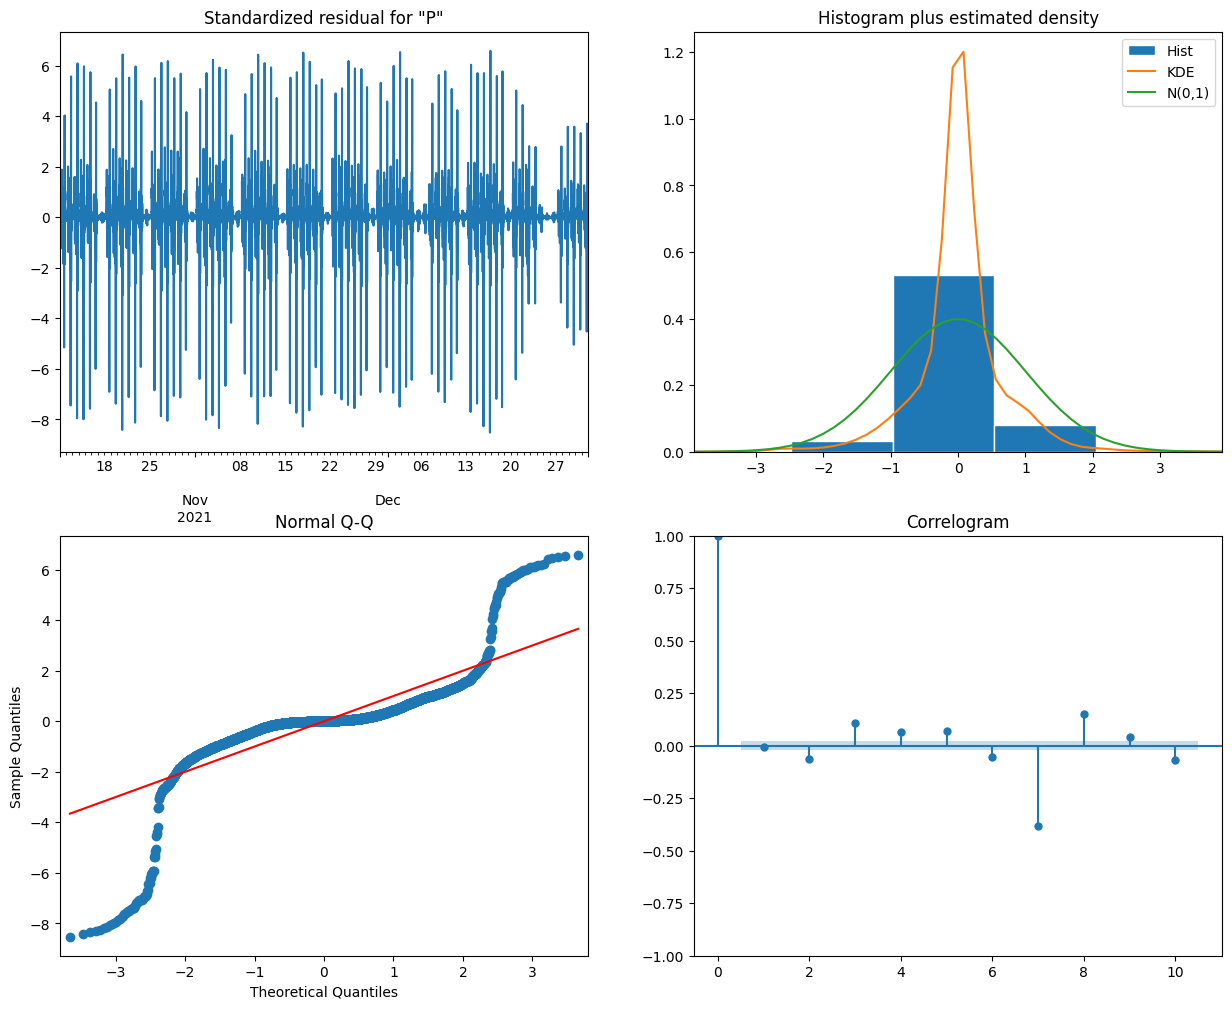

In [ ]:

# Fit the SARIMA model
model = SARIMAX(train_data['Parkings'], order=(p, d, q), seasonal_order=(P, D, Q, m))
sarima_results = model.fit()

# Model diagnostics
#sarima_results.plot_diagnostics(figsize=(15, 12))
#plt.show()


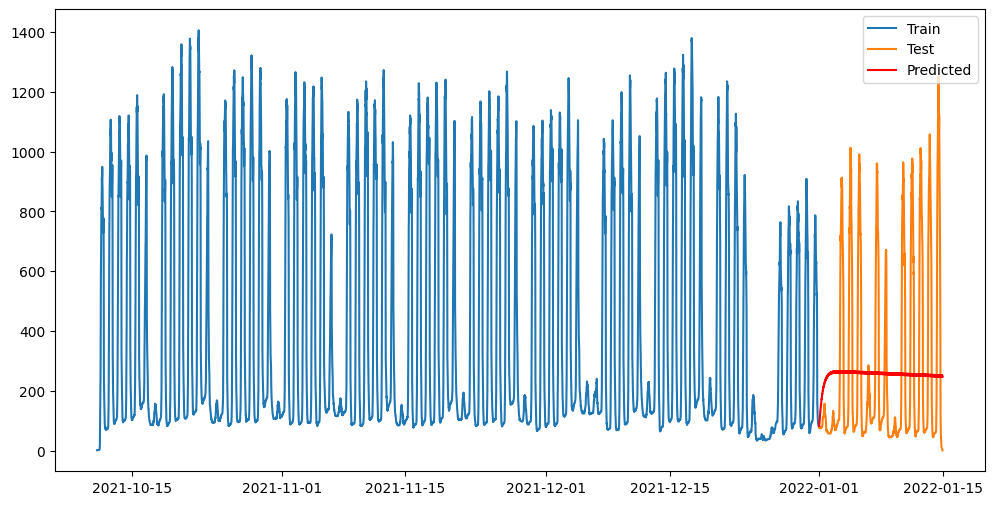

In [ ]:
# Make predictions
sarima_pred = sarima_results.predict(start=test_data.index[0], end=test_data.index[-1])

# Plot the actual vs predicted values
plt.figure(figsize=(12, 6))
plt.plot(train_data.index, train_data['Parkings'], label='Train')
plt.plot(test_data.index, test_data['Parkings'], label='Test')
plt.plot(test_data.index, sarima_pred, label='Predicted', color='red')
plt.legend()
plt.show()